**Modelos: árbol de decisión, kNN y Random Forest**

**Objetivo:** ajustar los hiperparámetros de cada modelo con el código común del grupo (mismos datos, mismos folds, mismas métricas y mismo Pipeline), analizar el sobreajuste y guardar los resultados para compararlos con los del resto del grupo.

El conjunto de test no se usa en este notebook: se evalúa una sola vez al final, con el modelo elegido entre todos los del grupo.

# Librerías

In [1]:
import time

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from imblearn.over_sampling import SMOTE
from sklearn import set_config
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import ValidationCurveDisplay, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.utils.class_weight import compute_class_weight

import utils.constantes as cte
from utils import modelado as mod

%matplotlib inline

np.random.seed(cte.semilla)

# 1. Datos

Se cargan los datos preparados en el EDA (limpios y codificados, con sus nulos) con la partición 80/20 estratificada común. A partir de aquí solo se usan `X_train` e `y_train`.

In [2]:
X_train, X_test, y_train, y_test = mod.cargar_datos()

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporción de clases en train:", y_train.value_counts(normalize=True).sort_index().round(2).to_dict())

Train: (1803, 30) | Test: (451, 30)
Proporción de clases en train: {0: 0.5, 1: 0.3, 2: 0.2}


**Curvas de validación.** La tabla de resultados solo muestra la diferencia entre train y validación de la mejor combinación. Para justificar esa elección frente a las demás, se mueve un hiperparámetro, se dejan los demás en su mejor valor y se representan train y validación (media ± desviación entre folds). Si el train mejora y la validación no, el modelo está memorizando en lugar de generalizar.

In [3]:
def curva_validacion(busqueda, parametro, valores, titulo):
    """Train y validación (media ± desviación) al mover un hiperparámetro, con el resto en su mejor valor."""
    ValidationCurveDisplay.from_estimator(
        busqueda.best_estimator_, X_train, y_train,
        param_name=parametro, param_range=valores,
        cv=mod.validador, scoring=mod.metrica,      # mismos folds y misma métrica que la búsqueda
        std_display_style="fill_between", n_jobs=-1)
    plt.title(titulo)
    plt.ylabel("F1 macro")                         # en la leyenda, "Test" es el fold de validación
    plt.show()

# 2. Experimento de balanceo

Antes de ajustar los modelos se comprueba qué técnica de balanceo conviene. Se comparan cuatro opciones con varias métricas:

- **Sin balancear:** la referencia, para saber si balancear aporta algo.
- **`class_weight="balanced"`:** aprendizaje sensible al coste; da más peso a los errores en las clases minoritarias.
- **SMOTENC:** genera pacientes sintéticos de las clases minoritarias sin inventar valores en las variables binarias y categóricas.
- **Tomek:** elimina pacientes de las clases mayoritarias que están muy cerca de los de otra clase, para limpiar la frontera.

El experimento se hace con el árbol y con kNN. Cada opción se ajusta con la misma rejilla de hiperparámetros, para que la comparación sea justa. Las búsquedas con SMOTENC se reutilizan después en las secciones 3 y 4.

**Pipeline común.** Todos los modelos usan el mismo `Pipeline` de `utils/modelado.py`: las variables numéricas se imputan con la mediana y se escalan con `RobustScaler`, las categóricas pasan sin cambios, después se aplica el balanceo y por último el modelo. El diagrama muestra el orden de los pasos y qué columnas pasan por cada uno (se puede desplegar cada caja):

In [4]:
set_config(display="diagram")   # los Pipeline se muestran como un diagrama desplegable

# pipeline común: imputar y escalar las numéricas, dejar las categóricas, balancear y modelo
mod.crear_pipeline(DecisionTreeClassifier(random_state=cte.semilla))

,steps,"[('preprocesado', ...), ('balanceo', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for form

In [5]:
# rejillas que se usan aquí y en las secciones 3 y 4
rejilla_arbol = {
    "modelo__criterion": ["gini", "entropy"],
    "modelo__max_depth": [3, 5, 8, 12, None],
    "modelo__min_samples_leaf": [1, 5, 20],
}
rejilla_knn = {
    "modelo__n_neighbors": [3, 5, 11, 21, 31, 51, 75],
    "modelo__metric": ["euclidean", "manhattan"],   # distancia en línea recta o sumando las diferencias de cada variable
}

busquedas_arbol, busquedas_knn, tablas_balanceo = {}, {}, []

# árbol: las cuatro opciones
for balanceo in [None, "class_weight", "smotenc", "tomek"]:
    busqueda = mod.crear_busqueda(mod.crear_pipeline(DecisionTreeClassifier(random_state=cte.semilla), balanceo=balanceo), rejilla_arbol)
    busquedas_arbol[balanceo] = busqueda.fit(X_train, y_train)
    tablas_balanceo.append(mod.tabla_resultados(busqueda, f"árbol | {balanceo}"))

# kNN no admite class_weight: sin balancear, con SMOTENC y con Tomek
for balanceo in [None, "smotenc", "tomek"]:
    busqueda = mod.crear_busqueda(mod.crear_pipeline(KNeighborsClassifier(), balanceo=balanceo), rejilla_knn)
    busquedas_knn[balanceo] = busqueda.fit(X_train, y_train)
    tablas_balanceo.append(mod.tabla_resultados(busqueda, f"kNN | {balanceo}"))

balanceo_resultados = pd.concat(tablas_balanceo)
balanceo_resultados[["f1_macro_val", "f1_macro_val_std", "recall_alto_val", "recall_alto_val_std",
 "precision_alto_val", "diferencia_train_val", "mejores_parametros"]].round(3)

,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val,mejores_parametros
modelo,,,,,,,
árbol | None,0.545,0.010,0.504,0.028,0.552,0.117,"{'modelo__criterion': 'entropy', 'modelo__max_..."
árbol | class_weight,0.532,0.022,0.596,0.038,0.460,0.147,"{'modelo__criterion': 'gini', 'modelo__max_dep..."
árbol | smotenc,0.541,0.033,0.596,0.020,0.504,0.326,"{'modelo__criterion': 'entropy', 'modelo__max_..."
árbol | tomek,0.540,0.016,0.524,0.060,0.511,0.404,"{'modelo__criterion': 'entropy', 'modelo__max_..."
kNN | None,0.537,0.022,0.410,0.050,0.802,0.032,"{'modelo__metric': 'manhattan', 'modelo__n_nei..."
kNN | smotenc,0.590,0.020,0.773,0.069,0.562,0.045,"{'modelo__metric': 'manhattan', 'modelo__n_nei..."
kNN | tomek,0.549,0.015,0.485,0.073,0.754,0.070,"{'modelo__metric': 'manhattan', 'modelo__n_nei..."


**Qué hace cada balanceo con las clases.** La tabla de métricas indica qué opción gana, pero no qué les pasa a los datos. Se cuentan los pacientes de cada clase en el train después de aplicar cada técnica. `class_weight` no cambia los pacientes, sino el peso del error en cada clase, así que se muestran sus pesos:

Pesos de class_weight: {'bajo': 0.67, 'moderado': 1.11, 'alto': 1.66}


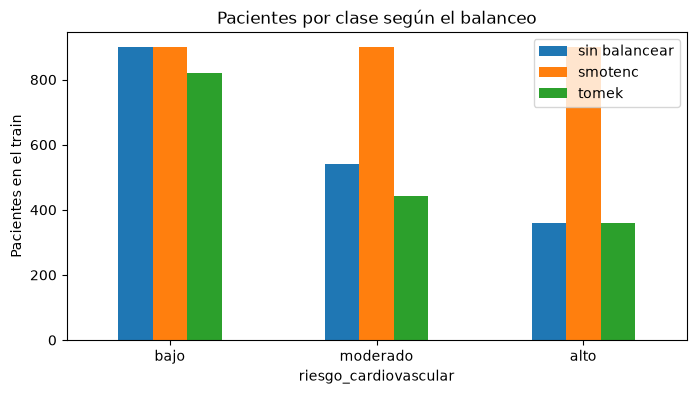

,sin balancear,smotenc,tomek
riesgo_cardiovascular,,,
bajo,901,901,819
moderado,541,901,441
alto,361,901,361


In [6]:
nombres_clase = {0: "bajo", 1: "moderado", 2: "alto"}
recuentos = {"sin balancear": y_train.value_counts()}
for balanceo in ["smotenc", "tomek"]:
    # [:-1] = el pipeline sin el modelo: solo preprocesado y balanceo
    _, y_res = mod.crear_pipeline(DecisionTreeClassifier(), balanceo=balanceo)[:-1].fit_resample(X_train, y_train)
    recuentos[balanceo] = pd.Series(y_res).value_counts()
recuentos = pd.DataFrame(recuentos).sort_index().rename(index=nombres_clase)

# class_weight no cambia los pacientes, sino lo que pesa el error en cada clase
pesos = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=y_train)
print("Pesos de class_weight:", dict(zip(nombres_clase.values(), pesos.round(2).tolist())))

recuentos.plot.bar(figsize=(8, 4), rot=0)
plt.ylabel("Pacientes en el train")
plt.title("Pacientes por clase según el balanceo")
plt.show()
recuentos

**SMOTENC frente a SMOTE.** SMOTE trata todas las variables como continuas e interpola entre pacientes, así que en las variables binarias y categóricas puede inventar valores imposibles (por ejemplo, un fumador "0,67"). SMOTENC asigna a esas variables la categoría más frecuente entre los vecinos. Se comprueba comparando los pacientes sintéticos de las dos técnicas con el mismo preprocesado:

In [7]:
prep = mod.crear_pipeline(DecisionTreeClassifier())[:-1]          # preprocesado + SMOTENC
X_res, _ = prep.fit_resample(X_train, y_train)
columnas = mod.numericas + mod.categoricas                        # orden de salida del ColumnTransformer
sinteticos_nc = pd.DataFrame(X_res[len(X_train):], columns=columnas)   # los sintéticos van al final

# mismo preprocesado, pero con SMOTE normal, que trata todo como continuo
X_prep = prep.named_steps["preprocesado"].transform(X_train)
X_smote, _ = SMOTE(random_state=cte.semilla).fit_resample(X_prep, y_train)
sinteticos_smote = pd.DataFrame(X_smote[len(X_train):], columns=columnas)

print("Pacientes sintéticos:", len(sinteticos_nc))
print("Valores con decimales en las categóricas con SMOTENC:", (sinteticos_nc[mod.categoricas] % 1 != 0).sum().sum())
print("Valores con decimales en las categóricas con SMOTE:  ", (sinteticos_smote[mod.categoricas] % 1 != 0).sum().sum())
# ejemplos de pacientes de SMOTE con un valor imposible en fumador_actual
sinteticos_smote.loc[sinteticos_smote["fumador_actual"] % 1 != 0, ["fumador_actual", "diabetes_mellitus", "nivel_actividad"]].head().round(2)

Pacientes sintéticos: 900
Valores con decimales en las categóricas con SMOTENC: 0
Valores con decimales en las categóricas con SMOTE:   2967


,fumador_actual,diabetes_mellitus,nivel_actividad
4,0.67,0.00,1.00
11,0.96,1.00,0.00
34,0.43,0.57,1.57
38,0.44,1.00,0.44
39,0.76,0.00,0.76


**Conclusión.**

- Balancear mejora claramente la métrica crítica. En el árbol, el recall de riesgo alto sube de 0,50 a 0,60 tanto con `class_weight` como con SMOTENC, y en kNN la mejora es mayor: de 0,41 a 0,77 con SMOTENC.
- El coste es una menor precisión de riesgo alto (en kNN, de 0,80 a 0,56), es decir, más falsas alarmas. Desde el punto de vista clínico compensa, porque no detectar a un paciente de riesgo alto es más grave que hacer pruebas innecesarias a uno que no lo es.
- Tomek apenas aporta. Solo elimina los pacientes de las clases mayoritarias que están en la frontera con otra clase: en el train quita 182 (82 de riesgo bajo y 100 moderados) y no elimina a ninguno de riesgo alto, así que el desbalance se mantiene (819 / 441 / 361), mientras que SMOTENC iguala las tres clases a 901. En el árbol empata en F1 macro (0,540), pero su recall de riesgo alto (0,52) queda por debajo del de `class_weight` y SMOTENC (0,60). En kNN el recall de riesgo alto solo sube de 0,41 a 0,49, lejos del 0,77 de SMOTENC.
- En el árbol, las cuatro opciones empatan en F1 macro (entre 0,532 y 0,545, dentro de la desviación entre folds), así que se desempata con el recall de riesgo alto. `class_weight` y SMOTENC empatan también ahí (0,596), pero SMOTENC tiene algo más de precisión de riesgo alto (0,504 frente a 0,460), así que se elige **SMOTENC**.
- En kNN, SMOTENC tiene el F1 macro más alto (0,590, frente a 0,537 sin balancear y 0,549 con Tomek), así que también se elige **SMOTENC**.
- Con el mismo preprocesado, SMOTE deja 2.967 valores con decimales en las variables categóricas de sus 900 pacientes sintéticos (de 9.900), y SMOTENC ninguno. Por eso se usa SMOTENC y no SMOTE.
- Random Forest se compara con las mismas cuatro opciones en la sección 5.
- El árbol con SMOTENC sobreajusta más (diferencia train-validación de 0,33 frente a 0,12 sin balancear), porque la búsqueda elige un árbol más profundo. Se analiza en la sección 3.

# 3. Árbol de decisión

Primero se entrena un árbol sencillo para ver su tamaño y después se busca la mejor combinación de hiperparámetros:

- `criterion`: medida de la pureza de los nodos (`gini` o `entropy`).
- `max_depth`: profundidad máxima. A mayor profundidad, más se ajusta al train y mayor es el riesgo de sobreajuste.
- `min_samples_leaf`: número mínimo de pacientes por hoja. Cuanto mayor, más sencillo es el árbol.

No se incluye `min_samples_split` (pacientes mínimos para dividir un nodo): con 5 o más pacientes por hoja, los valores 2 y 10 daban exactamente el mismo resultado, así que no aportaba nada.

In [8]:
# árbol de partida, sin ajustar
arbol = mod.crear_pipeline(DecisionTreeClassifier(max_depth=5, criterion="gini", random_state=cte.semilla))
arbol.fit(X_train, y_train)

print(f"Profundidad del árbol: {arbol.named_steps['modelo'].get_depth()}")
print(f"Número de nodos terminales: {arbol.named_steps['modelo'].get_n_leaves()}")

Profundidad del árbol: 5
Número de nodos terminales: 27


In [9]:
# la búsqueda con SMOTENC ya está hecha en el experimento de balanceo
busqueda_arbol = busquedas_arbol["smotenc"]

mejor_arbol = busqueda_arbol.best_estimator_.named_steps["modelo"]
print("Mejores parámetros:", busqueda_arbol.best_params_)
print(f"Profundidad del árbol: {mejor_arbol.get_depth()}")
print(f"Número de nodos terminales: {mejor_arbol.get_n_leaves()}")

Mejores parámetros: {'modelo__criterion': 'entropy', 'modelo__max_depth': None, 'modelo__min_samples_leaf': 5}
Profundidad del árbol: 17
Número de nodos terminales: 268


In [10]:
tabla_arbol = mod.tabla_resultados(busqueda_arbol, "arbol")
mod.guardar_resultados(busqueda_arbol, "arbol")
tabla_arbol.round(3)

,f1_macro_train,f1_macro_train_std,f1_macro_val,f1_macro_val_std,precision_macro_train,precision_macro_train_std,precision_macro_val,precision_macro_val_std,recall_macro_train,recall_macro_train_std,...,recall_alto_train,recall_alto_train_std,recall_alto_val,recall_alto_val_std,precision_alto_train,precision_alto_train_std,precision_alto_val,precision_alto_val_std,diferencia_train_val,mejores_parametros
modelo,,,,,,,,,,,,,,,,,,,,,
arbol,0.867,0.003,0.541,0.033,0.866,0.003,0.537,0.033,0.869,0.004,...,0.872,0.016,0.596,0.02,0.862,0.015,0.504,0.033,0.326,"{'modelo__criterion': 'entropy', 'modelo__max_..."


Las 5 mejores combinaciones, con su F1 en train, para comprobar si alguna es casi igual de buena pero sobreajusta menos:

In [11]:
resultados_arbol = pd.DataFrame(busqueda_arbol.cv_results_)
resultados_arbol[["param_modelo__criterion", "param_modelo__max_depth", "param_modelo__min_samples_leaf",
                  "mean_train_f1_macro", "mean_test_f1_macro", "std_test_f1_macro"]] \
    .sort_values("mean_test_f1_macro", ascending=False).head(5).round(3)

,param_modelo__criterion,param_modelo__max_depth,param_modelo__min_samples_leaf,mean_train_f1_macro,mean_test_f1_macro,std_test_f1_macro
28,entropy,None,5,0.867,0.541,0.033
11,gini,12,20,0.693,0.540,0.008
14,gini,None,20,0.693,0.540,0.008
8,gini,8,20,0.676,0.534,0.014
29,entropy,None,20,0.692,0.533,0.015


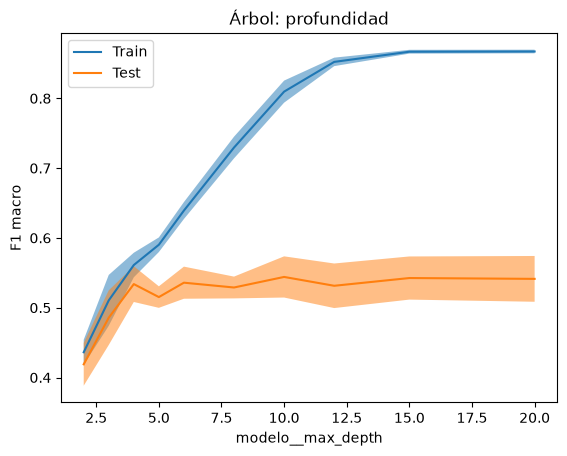

In [12]:
curva_validacion(busqueda_arbol, "modelo__max_depth", [2, 3, 4, 5, 6, 8, 10, 12, 15, 20], "Árbol: profundidad")

**Primeras decisiones del árbol.** Se representan solo los 3 primeros niveles, que sirven para comparar su interpretabilidad con la de kNN y Random Forest, que no se pueden leer de esta forma.

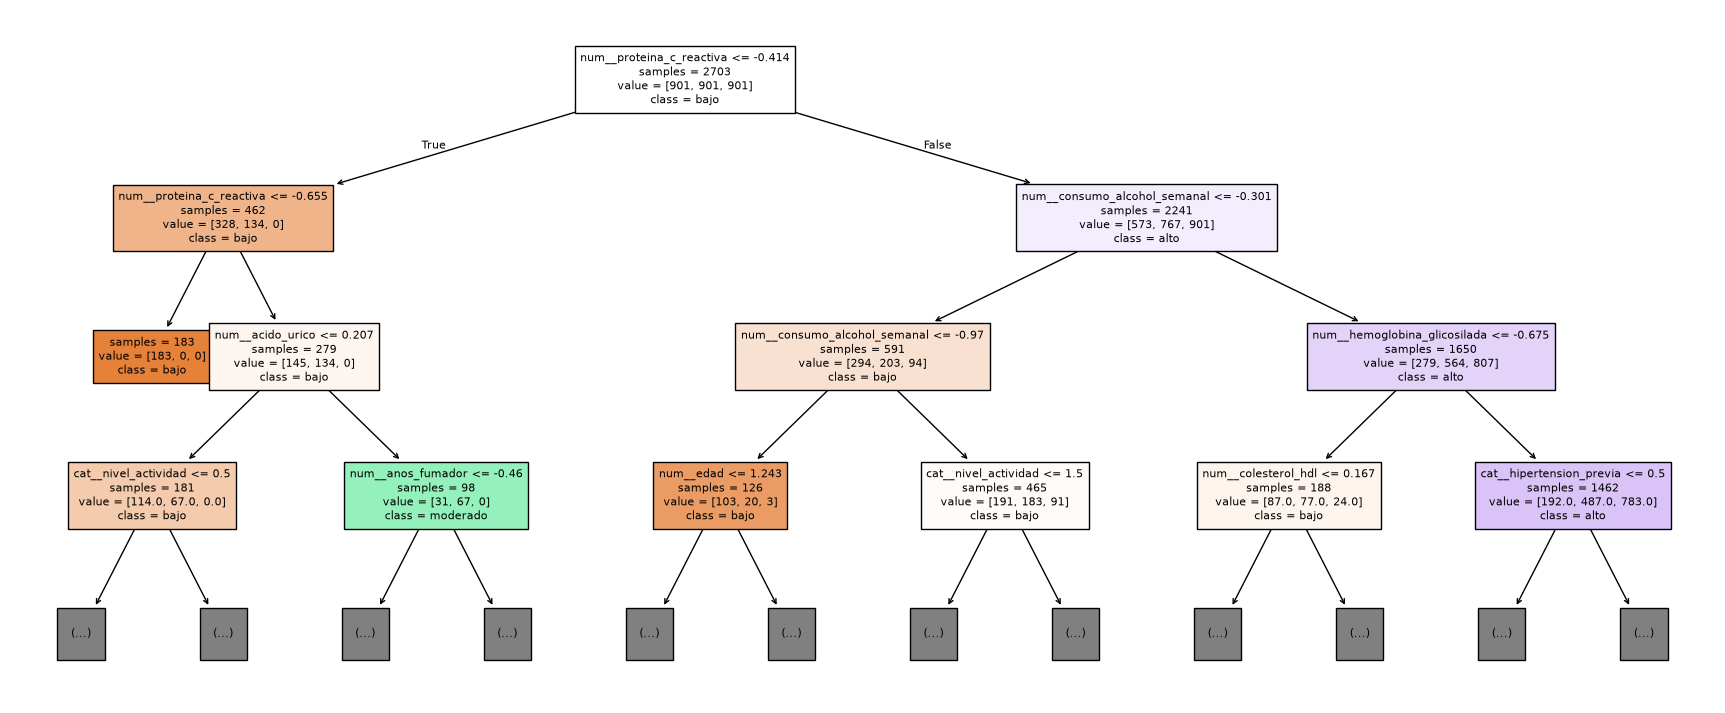

In [13]:
nombres_arbol = busqueda_arbol.best_estimator_.named_steps["preprocesado"].get_feature_names_out()

plt.figure(figsize=(22, 9))
plot_tree(mejor_arbol, max_depth=3, feature_names=nombres_arbol, class_names=["bajo", "moderado", "alto"],
          filled=True, impurity=False, fontsize=8)
plt.show()

**Umbrales en unidades clínicas.** El árbol trabaja después del `RobustScaler`, así que los umbrales del dibujo están en unidades escaladas. Se pueden devolver a las unidades originales con lo que aprendió el escalador con el train: valor real = valor escalado × rango intercuartílico + mediana.

In [14]:
# mediana (center_) e IQR (scale_) que aprendió el RobustScaler con el train
escalador = (busqueda_arbol.best_estimator_.named_steps["preprocesado"]
             .named_transformers_["num"].named_steps["escalar"])
mediana = pd.Series(escalador.center_, index=mod.numericas)
iqr = pd.Series(escalador.scale_, index=mod.numericas)

arbol_interno = mejor_arbol.tree_
for nodo, nivel in [(0, "raíz"), (arbol_interno.children_left[0], "izquierda"), (arbol_interno.children_right[0], "derecha")]:
    if arbol_interno.feature[nodo] < 0:                                     # una hoja no tiene umbral
        print(f"{nivel}: hoja")
        continue
    variable = nombres_arbol[arbol_interno.feature[nodo]].split("__")[1]   # quita el prefijo "num__"
    umbral = arbol_interno.threshold[nodo]
    if variable in mod.numericas:
        umbral = umbral * iqr[variable] + mediana[variable]                 # deshace el escalado
    print(f"{nivel}: {variable} <= {umbral:.2f}")

raíz: proteina_c_reactiva <= 0.97
izquierda: proteina_c_reactiva <= 0.50
derecha: consumo_alcohol_semanal <= 2.93


**Conclusión.**

- La mejor combinación es `entropy`, sin límite de profundidad y 5 pacientes por hoja: un árbol de 17 niveles y 268 hojas, con un F1 macro de 0,541 ± 0,033 en validación y un recall de riesgo alto de 0,60.
- Presenta un sobreajuste importante: 0,867 en train frente a 0,541 en validación. La curva de validación lo confirma, porque a partir de la profundidad 4 la validación oscila entre 0,51 y 0,54 mientras el train sigue subiendo hasta 0,87. La profundidad adicional solo sirve para memorizar pacientes del train.
- Existe una alternativa igual de buena y más sencilla: `gini`, profundidad 12 y 20 pacientes por hoja obtiene 0,540 ± 0,008 en validación (un empate), pero solo 0,693 en train y la mitad de variación entre folds. Si se eligiera el árbol, sería preferible esta combinación, porque generaliza igual con menos sobreajuste.
- Es el modelo más interpretable. Las primeras divisiones usan la proteína C reactiva, el consumo de alcohol y la hemoglobina glicosilada, las mismas variables que el EDA señaló como más relacionadas con el riesgo. Los umbrales del dibujo están en unidades escaladas (por el `RobustScaler`), pero se pueden devolver a las originales: la raíz separa con una proteína C reactiva de 0,97 mg/L, y la rama derecha con un consumo de alcohol de 2,93 unidades de bebida a la semana. El primer corte coincide casi con el umbral de 1 mg/L que la AHA y los CDC usan para el riesgo cardiovascular bajo, y el árbol ha llegado a él solo a partir de los datos. Hay que tener en cuenta que los recuentos de la raíz incluyen los pacientes sintéticos de SMOTENC.
- Es el que peor rendimiento tiene de los tres: de los 361 pacientes de riesgo alto del train, 37 (un 10 %) se clasifican como riesgo bajo, que es el error más grave.

# 4. kNN (k vecinos más cercanos)

kNN clasifica a cada paciente según la clase de sus `n_neighbors` vecinos más cercanos. Con pocos vecinos el modelo es muy flexible y se ajusta al ruido del train (sobreajuste); con muchos, se vuelve demasiado simple (subajuste).

Como se basa en distancias, necesita las variables escaladas, de lo que se encarga el `RobustScaler` del Pipeline.

In [15]:
# la búsqueda con SMOTENC ya está hecha en el experimento de balanceo (rejilla_knn)
busqueda_knn = busquedas_knn["smotenc"]
print("Mejores parámetros:", busqueda_knn.best_params_)

Mejores parámetros: {'modelo__metric': 'manhattan', 'modelo__n_neighbors': 51}


In [16]:
tabla_knn = mod.tabla_resultados(busqueda_knn, "knn")
mod.guardar_resultados(busqueda_knn, "knn")
tabla_knn.round(3)

,f1_macro_train,f1_macro_train_std,f1_macro_val,f1_macro_val_std,precision_macro_train,precision_macro_train_std,precision_macro_val,precision_macro_val_std,recall_macro_train,recall_macro_train_std,...,recall_alto_train,recall_alto_train_std,recall_alto_val,recall_alto_val_std,precision_alto_train,precision_alto_train_std,precision_alto_val,precision_alto_val_std,diferencia_train_val,mejores_parametros
modelo,,,,,,,,,,,,,,,,,,,,,
knn,0.635,0.015,0.59,0.02,0.641,0.014,0.598,0.021,0.669,0.013,...,0.851,0.017,0.773,0.069,0.606,0.029,0.562,0.04,0.045,"{'modelo__metric': 'manhattan', 'modelo__n_nei..."


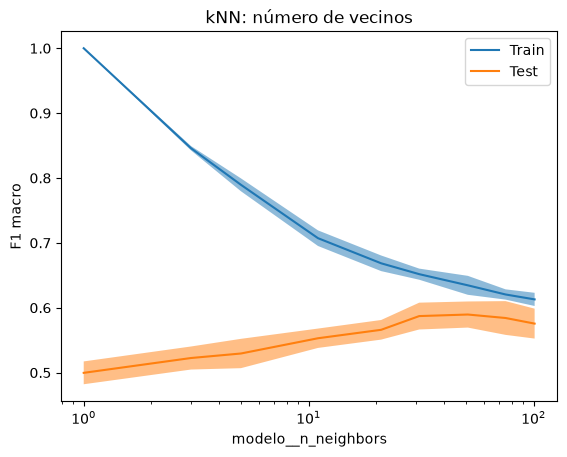

In [17]:
curva_validacion(busqueda_knn, "modelo__n_neighbors", [1, 3, 5, 11, 21, 31, 51, 75, 101], "kNN: número de vecinos")

**Conclusión.**

- La mejor combinación son 51 vecinos con distancia Manhattan, con un F1 macro de 0,590 ± 0,020 en validación y el mejor recall de riesgo alto de los tres modelos (0,77).
- Apenas sobreajusta: 0,635 en train frente a 0,590 en validación (diferencia de 0,045).
- La curva de validación refleja el compromiso entre sesgo y varianza. Con 1 vecino el train es perfecto (1,0) y la validación se queda en 0,50, porque el modelo memoriza a cada paciente. Al aumentar los vecinos, el train baja y la validación sube hasta estabilizarse entre 31 y 51, y con 75 o más empieza a bajar (subajuste). El valor elegido, 51, queda dentro de la rejilla y no en un extremo.
- Comete muy pocos errores graves: de los 361 pacientes de riesgo alto, solo 8 (un 2 %) se clasifican como riesgo bajo, y 74 como moderado.
- A cambio, genera muchas falsas alarmas: clasifica como moderado al 39 % de los pacientes de riesgo bajo y como alto al 30 % de los moderados. Su precisión de riesgo alto (0,56) queda lejos de la de Random Forest (0,65).

# 5. Random Forest

Random Forest es un ensemble de tipo **bagging**: entrena muchos árboles, cada uno con una muestra bootstrap de los pacientes y con un subconjunto aleatorio de variables en cada división, y combina sus predicciones por votación. Al promediar árboles distintos reduce la varianza (el sobreajuste) de un único árbol.

- `n_estimators`: número de árboles.
- `max_depth`: profundidad máxima de cada árbol.
- `max_features`: número de variables que se prueban en cada división. Cuantas menos, más distintos son los árboles entre sí.
- `min_samples_leaf`: número mínimo de pacientes por hoja. Limita cuánto memoriza cada árbol.

No se usa el error OOB para ajustarlo: en las versiones con SMOTENC los árboles también ven pacientes sintéticos dentro del Pipeline, y además así se valida con el mismo esquema que el resto del grupo.

Se ajusta con los mismos cuatro preprocesamientos de la sección 2 (sin balancear, `class_weight`, SMOTENC y Tomek), con la misma rejilla para todos, y se elige uno con el mismo criterio: el F1 macro y, si hay empate dentro de la desviación entre folds, el recall de riesgo alto.

In [18]:
rejilla_rf = {
    "modelo__n_estimators": [100, 300],
    "modelo__max_depth": [5, 10, None],
    "modelo__max_features": ["sqrt", 0.5],
    "modelo__min_samples_leaf": [1, 5, 10],
}

busquedas_rf, tablas_rf = {}, []
for balanceo in [None, "class_weight", "smotenc", "tomek"]:
    busqueda = mod.crear_busqueda(mod.crear_pipeline(RandomForestClassifier(random_state=cte.semilla), balanceo=balanceo), rejilla_rf)
    busquedas_rf[balanceo] = busqueda.fit(X_train, y_train)
    tablas_rf.append(mod.tabla_resultados(busqueda, f"random_forest | {balanceo}"))

balanceo_rf = pd.concat(tablas_rf)
balanceo_rf[["f1_macro_val", "f1_macro_val_std", "recall_alto_val", "recall_alto_val_std",
 "precision_alto_val", "diferencia_train_val", "mejores_parametros"]].round(3)

,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val,mejores_parametros
modelo,,,,,,,
random_forest | None,0.611,0.035,0.557,0.076,0.676,0.346,"{'modelo__max_depth': 10, 'modelo__max_feature..."
random_forest | class_weight,0.648,0.035,0.723,0.032,0.646,0.348,"{'modelo__max_depth': 10, 'modelo__max_feature..."
random_forest | smotenc,0.627,0.023,0.690,0.027,0.653,0.373,"{'modelo__max_depth': None, 'modelo__max_featu..."
random_forest | tomek,0.609,0.022,0.684,0.042,0.660,0.311,"{'modelo__max_depth': None, 'modelo__max_featu..."


**Elección.** `class_weight` obtiene el F1 macro más alto (0,648 ± 0,035), por delante de SMOTENC (0,627 ± 0,023), de la versión sin balancear (0,611 ± 0,035) y de Tomek (0,609 ± 0,022). La diferencia con SMOTENC (0,021) queda dentro de la desviación entre folds, así que se desempata con el recall de riesgo alto, que también es mayor con `class_weight` (0,72 frente a 0,69). Se elige **`class_weight`**: es la versión que se analiza en el resto de la sección y la que se guarda en `resultados/`.

Con `class_weight` la búsqueda elige árboles de profundidad máxima 10, mientras que con SMOTENC y con Tomek los elige sin límite de profundidad.

In [19]:
# balanceo elegido (ver la elección del apartado)
busqueda_rf = busquedas_rf["class_weight"]
print("Mejores parámetros:", busqueda_rf.best_params_)

Mejores parámetros: {'modelo__max_depth': 10, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 300}


In [20]:
tabla_rf = mod.tabla_resultados(busqueda_rf, "random_forest")
mod.guardar_resultados(busqueda_rf, "random_forest")
tabla_rf.round(3)

,f1_macro_train,f1_macro_train_std,f1_macro_val,f1_macro_val_std,precision_macro_train,precision_macro_train_std,precision_macro_val,precision_macro_val_std,recall_macro_train,recall_macro_train_std,...,recall_alto_train,recall_alto_train_std,recall_alto_val,recall_alto_val_std,precision_alto_train,precision_alto_train_std,precision_alto_val,precision_alto_val_std,diferencia_train_val,mejores_parametros
modelo,,,,,,,,,,,,,,,,,,,,,
random_forest,0.997,0.002,0.648,0.035,0.995,0.002,0.643,0.037,0.998,0.001,...,1.0,0.0,0.723,0.032,0.988,0.007,0.646,0.068,0.348,"{'modelo__max_depth': 10, 'modelo__max_feature..."


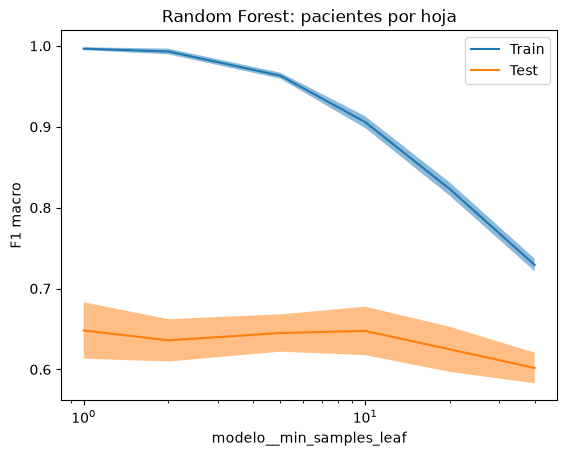

In [21]:
curva_validacion(busqueda_rf, "modelo__min_samples_leaf", [1, 2, 5, 10, 20, 40], "Random Forest: pacientes por hoja")

**Importancia de las variables.** Random Forest permite estimar qué variables utiliza más para decidir. Se analiza de dos formas:

- **Por impureza** (`feature_importances_`): cuánto mejora cada variable la pureza de los nodos. Es rápida, pero favorece a las variables continuas con muchos valores distintos.
- **Por permutación** (`permutation_importance`): cuánto empeora el F1 macro al desordenar cada variable. Se calcula en cada fold de **validación** y no en train, porque el Random Forest obtiene un F1 de casi 1 en train (0,997: memoriza a los pacientes): al desordenar una variable, las demás compensan su pérdida y casi todas aparecerían con importancia nula.

In [22]:
rf = busqueda_rf.best_estimator_.named_steps["modelo"]

# nombres de las variables a la salida del preprocesado (salen con prefijo, p. ej. "num__edad")
nombres = busqueda_rf.best_estimator_.named_steps["preprocesado"].get_feature_names_out()

importancia_impureza = pd.Series(rf.feature_importances_, index=nombres).sort_values(ascending=False)
importancia_impureza.head(10).round(3)

num__proteina_c_reactiva             0.110
num__consumo_alcohol_semanal         0.095
num__hemoglobina_glicosilada         0.066
num__acido_urico                     0.054
num__clearance_creatinina            0.047
num__glucosa_ayunas                  0.045
num__colesterol_hdl                  0.041
num__indice_masa_corporal            0.041
num__frecuencia_ejercicio_semanal    0.039
num__edad                            0.038
dtype: float64

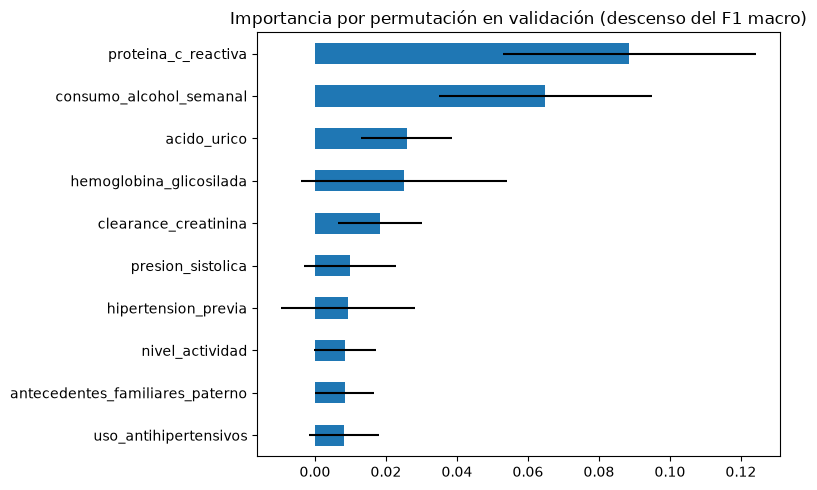

In [23]:
importancias = []
for idx_train, idx_val in mod.validador.split(X_train, y_train):
    # se entrena con 4 folds y se permuta sobre el fold que el modelo no ha visto
    modelo = clone(busqueda_rf.best_estimator_).fit(X_train.iloc[idx_train], y_train.iloc[idx_train])
    perm = permutation_importance(modelo, X_train.iloc[idx_val], y_train.iloc[idx_val], scoring=mod.metrica,
                                  n_repeats=10, random_state=cte.semilla, n_jobs=-1)
    importancias.append(perm.importances_mean)

importancias = pd.DataFrame(importancias, columns=X_train.columns)
top = importancias.mean().sort_values(ascending=False).head(10)
top.plot.barh(xerr=importancias[top.index].std(), figsize=(8, 5)).invert_yaxis()   # barra = media ± desviación entre folds
plt.title("Importancia por permutación en validación (descenso del F1 macro)")
plt.tight_layout()
plt.show()

**Conclusión.**

- La versión elegida (`class_weight`, con 300 árboles, profundidad máxima 10, `max_features="sqrt"` y 1 paciente por hoja) obtiene el mejor F1 macro de los tres modelos, **0,648 ± 0,035**, con un recall de riesgo alto de 0,72 y una precisión de riesgo alto de 0,65.
- Obtiene casi un 1,0 en train (0,997) porque cada árbol memoriza a los pacientes, pero aun así es el que mejor generaliza: 0,107 más en validación que el árbol individual. Es el comportamiento esperado del bagging, ya que cada árbol sobreajusta por separado, pero al promediar muchos árboles distintos se reduce la varianza.
- Limitar los pacientes por hoja reduce el sobreajuste sin perder rendimiento hasta cierto punto. Según la curva de validación, con 10 pacientes por hoja el train baja de 1,0 a 0,90 y la validación se mantiene en torno a 0,65; con 40, la validación cae a 0,60. Si se quisiera un modelo que memorice menos, 10 pacientes por hoja sería una alternativa igual de buena.
- Por permutación en validación, las variables más relevantes son la proteína C reactiva (0,089 ± 0,036) y el consumo de alcohol (0,065 ± 0,030), seguidas del ácido úrico (0,026 ± 0,013) y la hemoglobina glicosilada (0,025 ± 0,029, con mucha variación entre folds). Por impureza, las tres primeras son la proteína C reactiva (0,110), el alcohol (0,095) y la hemoglobina glicosilada (0,066). Coincide con el EDA, donde esas tres eran las más relacionadas con el riesgo (Spearman: alcohol 0,39, hemoglobina glicosilada 0,28 y proteína C reactiva 0,28).
- El colesterol (total, HDL y LDL), los triglicéridos, el uso de antihipertensivos, la frecuencia de ejercicio y los antecedentes familiares tienen una importancia por permutación dentro del ruido entre folds (por ejemplo, el HDL: 0,006 ± 0,011). Esto no significa que no estén relacionadas con el riesgo: en el EDA lo estaban el HDL (Spearman −0,20), el uso de antihipertensivos (0,24) y el ejercicio (−0,21), y en los antecedentes el riesgo alto pasaba del 12 % (ninguno) al 40 % (ambos). Significa que el modelo apenas pierde F1 cuando se desordenan, probablemente porque su efecto es pequeño frente al de la proteína C reactiva y el alcohol.

# 6. Comparación de los modelos

Se reúnen las tablas de los tres modelos. El criterio de elección es el F1 macro y, si dos modelos quedan dentro de la desviación entre folds, el recall de riesgo alto. Se añade el tiempo de entrenamiento como medida de complejidad, y una comparación fold a fold. El tiempo se mide entrenando cada modelo con todo el train y no con `mean_fit_time` de la búsqueda, que incluye el arranque de los procesos en paralelo y varía mucho de una ejecución a otra.

In [24]:
busquedas = {"arbol": busqueda_arbol, "knn": busqueda_knn, "random_forest": busqueda_rf}

comparacion = pd.concat([tabla_arbol, tabla_knn, tabla_rf])
def tiempo_entrenamiento(busqueda, repeticiones=3):
    """Segundos que tarda en entrenarse la mejor combinación con todo el train (el mínimo de varias repeticiones)."""
    tiempos = []
    for _ in range(repeticiones):
        inicio = time.perf_counter()
        clone(busqueda.best_estimator_).fit(X_train, y_train)
        tiempos.append(time.perf_counter() - inicio)
    return min(tiempos)   # el mínimo es el más estable: los demás incluyen interrupciones del sistema

comparacion["tiempo_entrenamiento_s"] = [tiempo_entrenamiento(b) for b in busquedas.values()]
comparacion[["f1_macro_val", "f1_macro_val_std", "recall_alto_val", "recall_alto_val_std",
             "precision_alto_val", "diferencia_train_val", "tiempo_entrenamiento_s"]] \
    .sort_values("f1_macro_val", ascending=False).round(3)

,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val,tiempo_entrenamiento_s
modelo,,,,,,,
random_forest,0.648,0.035,0.723,0.032,0.646,0.348,0.728
knn,0.590,0.020,0.773,0.069,0.562,0.045,0.116
arbol,0.541,0.033,0.596,0.020,0.504,0.326,0.153


**Comparación fold a fold.** Comparar la diferencia de medias con la desviación de cada modelo es poco riguroso. Como todos los modelos se validan con los mismos folds, se pueden comparar por pares: en cada fold, la diferencia de F1 macro entre Random Forest y kNN. Es el tipo de comparación que formaliza el test estadístico opcional.

In [25]:
folds = pd.DataFrame({n: pd.read_csv(mod.RUTA_RESULTADOS / f"{n}_folds.csv", index_col=0)["f1_macro"]
                      for n in ["arbol", "knn", "random_forest"]})
folds["rf_menos_knn"] = folds["random_forest"] - folds["knn"]   # mismos folds: la comparación es por pares
folds.round(3)

,arbol,knn,random_forest,rf_menos_knn
fold,,,,
0,0.590,0.574,0.632,0.058
1,0.530,0.603,0.668,0.065
2,0.489,0.562,0.619,0.057
3,0.551,0.619,0.707,0.088
4,0.547,0.590,0.615,0.025


**Matriz de confusión en validación.** La métrica crítica es el recall de riesgo alto, pero no distingue si un paciente de riesgo alto se clasifica como moderado o como bajo, que es mucho más grave. Solo la matriz de confusión lo muestra. Con `cross_val_predict`, cada paciente del train lo predice el modelo del fold en el que estaba en validación, así que no se usa el test.

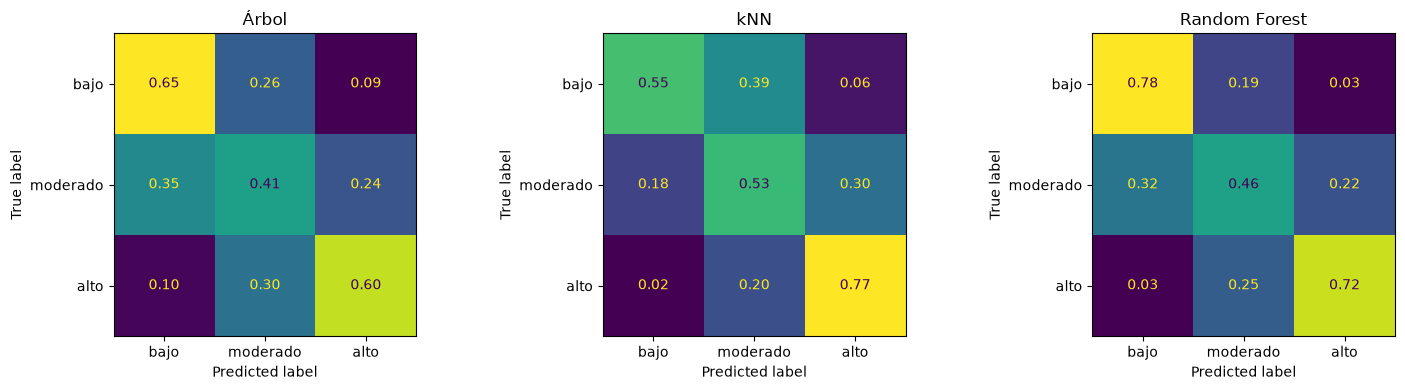

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nombre, busqueda) in zip(axes, [("Árbol", busqueda_arbol), ("kNN", busqueda_knn), ("Random Forest", busqueda_rf)]):
    # cada paciente lo predice el modelo del fold en el que estaba en validación
    y_pred = cross_val_predict(busqueda.best_estimator_, X_train, y_train, cv=mod.validador, n_jobs=-1)
    # normalize="true": cada fila suma 1, así la diagonal es el recall de cada clase
    ConfusionMatrixDisplay.from_predictions(y_train, y_pred, display_labels=["bajo", "moderado", "alto"],
                                            normalize="true", values_format=".2f", ax=ax, colorbar=False)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

**Conclusión.**

| | Árbol | kNN | Random Forest |
|---|---|---|---|
| Preprocesamiento elegido | SMOTENC | SMOTENC | `class_weight` |
| F1 macro (validación) | 0,541 ± 0,033 | 0,590 ± 0,020 | **0,648 ± 0,035** |
| Recall de riesgo alto | 0,60 | **0,77** | 0,72 |
| Riesgo alto clasificado como bajo | 37 (10 %) | **8 (2 %)** | 10 (3 %) |
| Precisión de riesgo alto | 0,50 | 0,56 | **0,65** |
| Diferencia train-validación | 0,33 | **0,05** | 0,35 |
| Tiempo de entrenamiento (todo el train) | Décimas de segundo | Décimas de segundo | Menos de 1 s |

- Según el criterio acordado, el mejor modelo es **Random Forest con `class_weight`**: tiene el F1 macro más alto y supera a kNN en los 5 folds, por 0,058, 0,065, 0,057, 0,088 y 0,025. Como la comparación es con los mismos folds, no se trata de un empate y no es necesario desempatar con el recall. Es el candidato de este notebook para la comparación final del grupo.
- Con `class_weight`, Random Forest se acerca a kNN en la métrica crítica: su recall de riesgo alto es 0,72 frente a 0,77, y solo clasifica como riesgo bajo a 10 pacientes de riesgo alto (3 %) frente a 8 (2 %). A cambio, genera muchas menos falsas alarmas: clasifica como moderado al 19 % de los pacientes de riesgo bajo (kNN, al 39 %) y como alto al 22 % de los moderados (kNN, al 30 %).
- El mejor preprocesamiento depende del modelo: SMOTENC en el árbol y en kNN, y `class_weight` en Random Forest, mientras que Tomek no es el mejor en ninguno. Esto justifica haber probado todas las opciones en cada modelo en lugar de fijar una para todos.
- kNN sigue siendo una alternativa interesante desde el punto de vista clínico por su recall y porque apenas sobreajusta, aunque con más falsas alarmas.
- El árbol se descarta por rendimiento, aunque es el único que se puede interpretar directamente y confirma qué variables utilizan los modelos para decidir.
- En cuanto a complejidad, Random Forest es el más costoso de entrenar (varias veces más lento que los otros dos; los valores exactos dependen de la carga del ordenador) y funciona como una caja negra, aunque la importancia de las variables ayuda a explicarlo. kNN apenas tarda en entrenarse porque solo almacena los pacientes, pero su coste está en la predicción, porque para cada paciente nuevo tiene que calcular la distancia a todos los del train.